# 04 · Experimentos: entender a la red (y la evaluación final)

En el notebook 03 vimos que la two-tower les gana a los baselines. Ahora queremos entender **por qué**, **para quién** y **a qué costo**. Son cinco preguntas:

| # | Pregunta | Cómo la respondemos |
|---|---|---|
| 1 | ¿Qué aporta cada pieza de la red? | **Ablaciones**: re-entrenamos la red sacándole una pieza por vez |
| 2 | ¿Los resultados son estables? | Re-entrenamos la red completa con **otras dos semillas** al azar |
| 3 | ¿El perfil ayuda a los tonos oscuros? ¿Qué pasa con *dark* y *tan*? | Resultados por grupo y por **cada uno de los 13 tonos** |
| 4 | ¿Cuánto cuesta diversificar? | **Penalizamos la popularidad** al recomendar y medimos qué se pierde |
| 5 | ¿Cuánto da todo en datos nunca vistos? | **Evaluación final en test**, una sola vez |

## ¿Qué es una ablación?

El nombre viene de la medicina (sacar una parte para ver qué función cumplía). En machine learning es **re-entrenar el modelo sin una pieza** y medir cuánto empeora. Si empeora mucho, esa pieza era importante. Cambiamos **una sola cosa por vez** y dejamos todo lo demás igual (misma configuración, mismas 10 épocas, misma semilla), para que la diferencia se deba solo a esa pieza.

| Variante | Qué le sacamos | Qué ve la red |
|---|---|---|
| **Red completa** | — | perfil + historial; ID + contenido |
| **Sin perfil** | tono, tipo de piel, ojos, pelo | la persona es solo su historial |
| **Sin historial** | lo que le gustó antes | la persona es solo su perfil |
| **Sin contenido** | marca, categorías, precio, ingredientes, highlights | el producto es solo su ID (como en ALS) |
| **Sin ID** | el vector propio de cada producto | el producto es solo su contenido |

Las variantes se entrenaron con `scripts/train_ablations.py` (~20 min cada una); acá cargamos los pesos guardados.

Las preguntas 1 a 4 se responden en **validación**. Test se usa una sola vez, en la sección 5.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="implicit")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
threadpool_limits(1, "blas")

from src.data import TONE_GROUP_ORDER, SKIN_TONE_ORDER, TONE_GROUPS, PROFILE_COLS
from src.splits import load_splits
from src.evaluate import ItemIndex, evaluate, summarize, by_tone
from src.baselines import Popularity, SegmentPopularity, ALSRecommender, ProfileToALS, PopularityPenalty
from src.two_tower import TwoTowerRecommender

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
VERDE, GRIS = "#2e8b57", "#9a9a9a"

s = load_splits()
idx = ItemIndex(s.items)
N = len(idx)
completo = s.users.index[(s.users[PROFILE_COLS] != "desconocido").all(axis=1)]

def eval_warm(m):
    return evaluate(m, s.val_warm, s.train, s.users, idx, exclude_train=True)

def eval_cold(m):  # cold start: solo personas con perfil completo (ver notebook 02)
    r = evaluate(m, s.val_cold, s.train, s.users, idx, exclude_train=False)
    return r[r.index.isin(completo)]

def pareada(a, b):
    # diferencia pareada (a − b) en puntos de recall, con intervalo del 95%
    d = a.recall - b.recall.reindex(a.index)
    return d.mean() * 100, 1.96 * d.std() / np.sqrt(len(d)) * 100

In [2]:
KW = dict(dim=128, hidden=512)
VARIANTES = {
    "Red completa": (ROOT / "models" / "two_tower.pt", {}),
    "Sin perfil": (ROOT / "models" / "ablaciones" / "sin_perfil.pt", {"use_profile": False}),
    "Sin historial": (ROOT / "models" / "ablaciones" / "sin_historial.pt", {"use_history": False}),
    "Sin contenido": (ROOT / "models" / "ablaciones" / "sin_contenido.pt", {"use_content": False}),
    "Sin ID": (ROOT / "models" / "ablaciones" / "sin_id.pt", {"use_item_id": False}),
    "Semilla 43": (ROOT / "models" / "ablaciones" / "semilla_43.pt", {}),
    "Semilla 44": (ROOT / "models" / "ablaciones" / "semilla_44.pt", {}),
}
modelos = {n: TwoTowerRecommender(s.train, s.users, s.items, idx, weights=p, **KW, **flags)
           for n, (p, flags) in VARIANTES.items()}

t0 = time.time()
rw = {n: eval_warm(m) for n, m in modelos.items()}
rc = {n: eval_cold(m) for n, m in modelos.items()}
print(f"Evaluación de {len(modelos)} modelos: {time.time() - t0:.0f} s")

Evaluación de 7 modelos: 86 s


## 1 · Ablaciones: ¿qué aporta cada pieza?

In [3]:
filas = []
for n in ["Red completa", "Sin perfil", "Sin historial", "Sin contenido", "Sin ID"]:
    dw, ew = pareada(rw[n], rw["Red completa"])
    dc, ec = pareada(rc[n], rc["Red completa"])
    filas.append({"variante": n,
                  "recall con historial": rw[n].recall.mean(), "Δ con historial (puntos)": dw, "± 95%": ew,
                  "recall cold start": rc[n].recall.mean(), "Δ cold start (puntos)": dc, "±  95%": ec,
                  "cobertura cold start": np.unique(np.concatenate(rc[n].top.to_numpy())).size / N})
abl = pd.DataFrame(filas).set_index("variante")
abl.to_csv(ROOT / "reports" / "04_ablaciones_val.csv")
abl.style.format({"recall con historial": "{:.2%}", "recall cold start": "{:.2%}", "cobertura cold start": "{:.1%}",
                  "Δ con historial (puntos)": "{:+.2f}", "Δ cold start (puntos)": "{:+.2f}",
                  "± 95%": "{:.2f}", "±  95%": "{:.2f}"})

,recall con historial,Δ con historial (puntos),± 95%,recall cold start,Δ cold start (puntos),± 95%,cobertura cold start
variante,,,,,,,
Red completa,18.53%,+0.00,0.00,10.30%,+0.00,0.00,2.8%
Sin perfil,18.54%,+0.00,0.24,8.02%,-2.28,0.30,0.4%
Sin historial,5.74%,-12.80,0.40,9.42%,-0.88,0.31,3.4%
Sin contenido,16.91%,-1.62,0.26,10.13%,-0.17,0.17,2.5%
Sin ID,17.95%,-0.58,0.22,10.38%,+0.08,0.16,2.9%


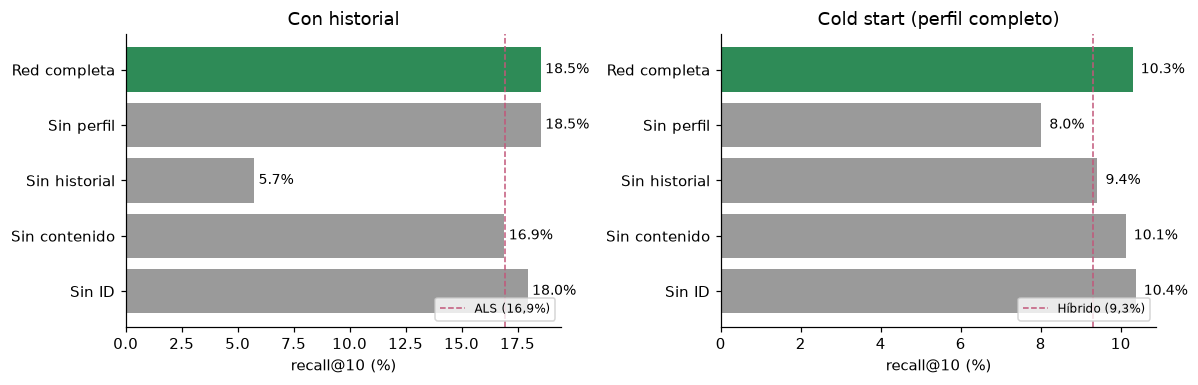

In [4]:
ref = {"ALS (16,9%)": 16.93, "Híbrido (9,3%)": 9.31}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, titulo, linea in [(axes[0], "recall con historial", "Con historial", "ALS (16,9%)"),
                               (axes[1], "recall cold start", "Cold start (perfil completo)", "Híbrido (9,3%)")]:
    v = abl[col] * 100
    ax.barh(v.index, v, color=[VERDE if n == "Red completa" else GRIS for n in v.index])
    for i, x in enumerate(v):
        ax.text(x + 0.2, i, f"{x:.1f}%", va="center", fontsize=9)
    ax.axvline(ref[linea], color="#c2577a", lw=1, ls="--", label=linea)
    ax.set(title=titulo, xlabel="recall@10 (%)")
    ax.invert_yaxis()
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "04_ablaciones.png", bbox_inches="tight")
plt.show()

**Cómo leerlo:** cada pieza importa en un escenario distinto.

| Pieza | Con historial | Cold start | Conclusión |
|---|---|---|---|
| **Perfil** | 0,0 puntos | **−2,3** | Solo sirve cuando no hay historial. Sin perfil, la red en cold start cae a nivel popularidad (8,0%) y recomienda los mismos 10 productos a todo el mundo (cobertura 0,4%). **Cuando conocemos tu historial, tu tipo de piel no agrega nada.** |
| **Historial** | **−12,8** | −0,9 | Es, por lejos, la pieza más importante. Sorpresa: sacarlo también empeora el cold start. Entrenar con historial obliga a la torre producto a aprender mejores vectores, y eso ayuda a todos. |
| **Contenido** (marca, categoría, ingredientes, highlights) | **−1,6** | −0,2 | Sin contenido, la red cae **exactamente** al nivel del ALS (16,9%). **La ventaja de la red con historial viene de conocer qué es cada producto.** |
| **ID del producto** | −0,6 | +0,1 | Casi no hace falta: el contenido alcanza. Es una buena noticia práctica: la red puede recomendar **productos nuevos** que nadie reseñó todavía, perdiendo muy poco. |

## 2 · ¿Los resultados son estables? Tres semillas

Una red neuronal arranca con pesos al azar y ve los datos en un orden al azar. La **semilla** fija ese azar. Si re-entrenamos con otra semilla, el resultado cambia un poco. Ese cambio es la "variabilidad de entrenamiento", y sirve de vara: **una diferencia entre variantes más chica que la variabilidad entre semillas no significa nada**.

In [5]:
sem = ["Red completa", "Semilla 43", "Semilla 44"]
t_sem = pd.DataFrame({"recall con historial": [rw[n].recall.mean() for n in sem],
                      "recall cold start": [rc[n].recall.mean() for n in sem]}, index=["Semilla 42 (la del notebook 03)", "Semilla 43", "Semilla 44"])
t_sem.loc["promedio"] = t_sem.mean()
t_sem.loc["desvío entre semillas"] = t_sem.iloc[:3].std()
t_sem.style.format("{:.2%}")

,recall con historial,recall cold start
Semilla 42 (la del notebook 03),18.53%,10.30%
Semilla 43,18.53%,10.34%
Semilla 44,18.50%,10.28%
promedio,18.52%,10.31%
desvío entre semillas,0.02%,0.03%


### ¿La lista del tono *dark* es real o es ruido?

En el notebook 03, una persona inventada de tono *dark* recibía una lista casi totalmente distinta a la de los demás tonos. Si eso es algo que la red **aprendió**, debería repetirse con otras semillas. Si es **ruido** (por tener pocos datos), cada semilla debería inventar una lista distinta.

Para cada uno de los 13 tonos armamos la misma persona inventada (piel mixta, ojos marrones, pelo negro, sin historial) y medimos cuántos productos de su top 10 se repiten entre semillas.

In [6]:
tonos = SKIN_TONE_ORDER
perf = pd.DataFrame([{"skin_tone": t, "skin_type": "combination", "eye_color": "brown", "hair_color": "black"} for t in tonos])
tops = {n: np.argsort(-modelos[n].score_profiles(perf), axis=1)[:, :10] for n in sem}
pares = [("Red completa", "Semilla 43"), ("Red completa", "Semilla 44"), ("Semilla 43", "Semilla 44")]
estab = pd.DataFrame({
    "personas en train": s.users.loc[s.users.index.isin(s.train.author_id)].skin_tone.value_counts().reindex(tonos).fillna(0).astype(int),
    "productos en común entre semillas (de 10)": [np.mean([len(set(tops[a][i]) & set(tops[b][i])) for a, b in pares]) for i in range(len(tonos))],
    "en común con la lista 'light' (promedio de semillas)": [np.mean([len(set(tops[n][i]) & set(tops[n][tonos.index("light")])) for n in sem]) for i in range(len(tonos))],
}, index=tonos)
estab.index.name = "tono"
estab.style.format({"productos en común entre semillas (de 10)": "{:.1f}", "en común con la lista 'light' (promedio de semillas)": "{:.1f}"}) \
     .background_gradient(subset=["productos en común entre semillas (de 10)"], cmap="RdPu_r", vmin=0, vmax=10)

,personas en train,productos en común entre semillas (de 10),en común con la lista 'light' (promedio de semillas)
tono,,,
porcelain,514,9.3,1.0
fair,72653,9.0,8.7
fairLight,19130,9.0,9.0
light,90384,8.7,10.0
lightMedium,70267,9.3,8.7
medium,24672,9.0,6.7
mediumTan,23092,10.0,8.0
olive,644,9.3,1.0
tan,12172,8.0,6.0


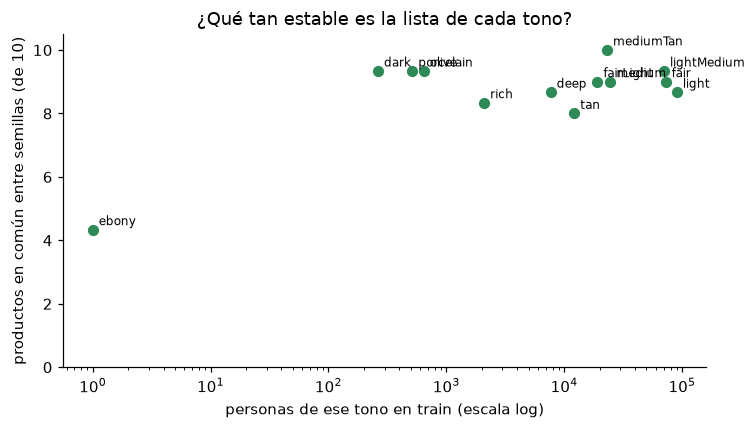

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(estab["personas en train"], estab["productos en común entre semillas (de 10)"], color=VERDE, s=40)
for t, r in estab.iterrows():
    ax.annotate(t, (r["personas en train"], r["productos en común entre semillas (de 10)"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set(xlabel="personas de ese tono en train (escala log)", ylabel="productos en común entre semillas (de 10)",
       title="¿Qué tan estable es la lista de cada tono?", ylim=(0, 10.5))
plt.tight_layout()
plt.savefig(FIG / "04_estabilidad_por_tono.png", bbox_inches="tight")
plt.show()

### ¿Por qué los tonos chicos tienen listas tan estables y tan distintas?

Si las listas de *dark*, *porcelain* y *olive* se repiten entre semillas, la red aprendió algo de esos grupos. Pero ¿qué? Miramos **qué reseñan** las personas de cada tono en train: qué proporción de sus positivos cae en sus 10 productos más frecuentes y en su marca más frecuente.

In [8]:
t_ = s.train.assign(tono=s.users.skin_tone.reindex(s.train.author_id).values)
marca = s.items.set_index("product_id").brand_name
filas = []
for tn, g in t_.groupby("tono"):
    vc = g.product_id.value_counts(normalize=True)
    mb = marca.reindex(g.product_id).value_counts(normalize=True)
    filas.append({"tono": tn, "personas": g.author_id.nunique(), "positivos": len(g),
                  "% en sus 10 productos más frecuentes": vc.head(10).sum(),
                  "marca más frecuente": mb.index[0], "% de esa marca": mb.iloc[0]})
conc = pd.DataFrame(filas).set_index("tono").reindex(SKIN_TONE_ORDER)
print("Productos más reseñados por las personas dark / porcelain / olive:")
for tn in ["dark", "porcelain", "olive"]:
    top5 = t_[t_.tono == tn].product_id.value_counts().head(5).index
    print(f"  {tn:>9}:", ", ".join(s.items.set_index("product_id").product_name.reindex(top5).str[:32]))
conc.style.format({"% en sus 10 productos más frecuentes": "{:.0%}", "% de esa marca": "{:.0%}",
                   "personas": "{:,.0f}", "positivos": "{:,.0f}"}) \
    .background_gradient(subset=["% en sus 10 productos más frecuentes"], cmap="RdPu", vmin=0, vmax=0.7)

Productos más reseñados por las personas dark / porcelain / olive:
       dark: Greek Yoghurt Foaming Cream Clea, Vinosource-Hydra Moisturizing So, Lip Sleeping Mask Intense Hydrat, Beauty Elixir Prep, Set, Glow Fa, Sugar Hydrating Lip Balm
  porcelain: Greek Yoghurt Foaming Cream Clea, Lip Sleeping Mask Intense Hydrat, Vinopure Natural Salicylic Acid , Lip Glowy Balm, Vinosource-Hydra Moisturizing So
      olive: Greek Yoghurt Foaming Cream Clea, Beauty Elixir Prep, Set, Glow Fa, Vinosource-Hydra Moisturizing So, Lip Sleeping Mask Intense Hydrat, Vinopure Natural Salicylic Acid 


,personas,positivos,% en sus 10 productos más frecuentes,marca más frecuente,% de esa marca
tono,,,,,
porcelain,514,608,58%,KORRES,29%
fair,"72,653","136,148",8%,Tatcha,4%
fairLight,"19,130","38,008",8%,Tatcha,5%
light,"90,384","175,548",7%,Tatcha,4%
lightMedium,"70,267","136,056",7%,Tatcha,5%
medium,"24,672","46,255",8%,Tatcha,5%
mediumTan,"23,092","42,587",8%,Tatcha,5%
olive,644,730,63%,Caudalie,32%
tan,"12,172","21,550",9%,The Ordinary,4%


**Cómo leerlo:**

- **Los resultados son muy estables entre semillas**: el recall varía apenas 0,02–0,03 puntos. Las diferencias de las ablaciones (0,6 a 12,8 puntos) son mucho más grandes, así que son reales.
- **Las listas también son estables**: para casi todos los tonos, 8 a 10 de los 10 productos se repiten entre semillas. La única excepción es *ebony*, con **una sola persona** en train: su lista es casi al azar.
- **Pero *porcelain*, *olive* y *dark* son raros**: sus listas son estables entre semillas y, a la vez, comparten **un solo producto** con la lista de *light*. Si fuera ruido, cambiarían con la semilla; no cambian. La red aprendió *algo* de esos grupos.
- **La tabla de concentración explica qué aprendió.** Las personas de esos tres tonos reseñan un conjunto muy chico de productos: **el 49–63% de sus positivos cae en solo 10 productos** (en los demás tonos, ~8%). Y entre el 19% y el 32% son de **una sola marca** (Caudalie o KORRES), contra un 4–5% en los demás. Comparten incluso los mismos productos (el limpiador *Greek Yoghurt* de KORRES, el *Vinosource* de Caudalie).

**Interpretación:** esos tres tonos no parecen venir del formulario general de Sephora, sino de reseñas asociadas a unas pocas marcas (por ejemplo, reseñas sindicadas desde los sitios de las marcas, o campañas de muestras). No son una muestra representativa de las personas con esos tonos de piel.

**Es un hallazgo importante de *fairness*:** la red le recomienda a una persona *dark* productos de Caudalie y KORRES, y en validación **acierta mucho** (porque las personas *dark* del dataset efectivamente reseñan eso). Pero eso no es personalización para pieles oscuras: es un artefacto de cómo se juntaron los datos. **Una métrica alta en un grupo chico puede esconder un sesgo de los datos.** Por eso conviene que *dark* esté agrupado con *deep*, *rich* y *ebony* en el grupo *oscuro*: dentro del grupo pesa poco (263 de ~10 mil personas).

## 3 · Fairness en profundidad

### ¿El perfil ayuda más a algunos grupos?

Comparamos la red completa contra la red **sin perfil**, grupo por grupo. En cold start, la red sin perfil no sabe nada de la persona: le recomienda lo mismo a todo el mundo. La diferencia entre las dos es **cuánto le sirve a cada grupo que la red conozca su piel**.

In [9]:
filas = []
for esc, res in [("Con historial", rw), ("Cold start", rc)]:
    for n in ["Red completa", "Sin perfil"]:
        bt = by_tone(res[n]).drop(index="desconocido", errors="ignore")
        filas.append(bt.assign(escenario=esc, variante=n))
tono = pd.concat(filas).rename_axis("tone_group").reset_index()
piv = tono.pivot_table(index="tone_group", columns=["escenario", "variante"], values="mean").loc[TONE_GROUP_ORDER]
aporte = pd.DataFrame({
    "con historial: completa − sin perfil": (piv[("Con historial", "Red completa")] - piv[("Con historial", "Sin perfil")]) * 100,
    "cold start: completa − sin perfil": (piv[("Cold start", "Red completa")] - piv[("Cold start", "Sin perfil")]) * 100,
    "personas (cold start)": tono[(tono.escenario == "Cold start") & (tono.variante == "Red completa")].set_index("tone_group")["size"],
})
display((piv * 100).round(2))
aporte.style.format({"con historial: completa − sin perfil": "{:+.2f}", "cold start: completa − sin perfil": "{:+.2f}"}) \
      .set_caption("Cuánto aporta el perfil a cada grupo (puntos de recall)")

escenario    Cold start            Con historial           
variante   Red completa Sin perfil  Red completa Sin perfil
tone_group                                                 
claro           10.9700     8.7700       17.9700    18.2600
light            9.7600     7.7700       17.7300    17.8200
medio           10.0300     7.5200       18.9000    19.0200
tan              9.2100     7.4600       18.0000    18.6200
oscuro          13.4700     9.7500       19.6200    18.3500

,con historial: completa − sin perfil,cold start: completa − sin perfil,personas (cold start)
tone_group,,,
claro,-0.29,+2.19,4740
light,-0.09,+1.98,4407
medio,-0.12,+2.51,6006
tan,-0.62,+1.75,681
oscuro,+1.27,+3.72,508


**Cómo leerlo:**

- **En cold start, el perfil ayuda a todos los grupos** (+1,8 a +3,7 puntos). **El grupo que más se beneficia es *oscuro* (+3,7)**: cuando la red no sabe nada de la persona, saber que tiene piel oscura le sirve más que a nadie. Tiene sentido: sin perfil, la red recomienda lo popular, y lo popular está dominado por las preferencias de las mayorías (tonos claros).
- **Con historial, el perfil no aporta** a ningún grupo, salvo un +1,3 para *oscuro* (con un margen de error de ~±2,3, no es concluyente).

Esto responde la pregunta del plan, *"¿el perfil achica la brecha?"*: **sí, en cold start el perfil es especialmente valioso para los tonos oscuros.** Sin él, la red les recomendaría a todos lo que les gusta a las mayorías.

### Los 13 tonos, uno por uno

Hasta ahora agrupamos los tonos en 5 grupos porque algunos son muy chicos. Miremos igual los 13, con su margen de error, sumando validación con historial y cold start para tener más casos.

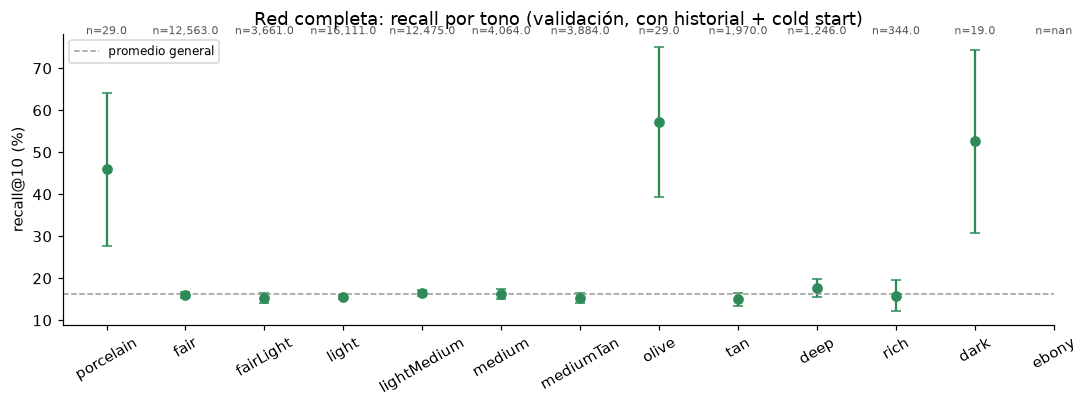

,grupo,mean,± 95%,size
skin_tone,,,,
porcelain,claro,0.4598,0.1817,29.0000
fair,claro,0.1602,0.0063,"12,563.0000"
fairLight,claro,0.1538,0.0114,"3,661.0000"
light,light,0.1555,0.0055,"16,111.0000"
lightMedium,medio,0.1652,0.0064,"12,475.0000"
medium,medio,0.1623,0.0112,"4,064.0000"
mediumTan,medio,0.1535,0.0111,"3,884.0000"
olive,medio,0.5718,0.1779,29.0000
tan,tan,0.1496,0.0155,"1,970.0000"


In [10]:
r_all = pd.concat([rw["Red completa"].assign(escenario="con historial"), rc["Red completa"].assign(escenario="cold start")])
r_all["skin_tone"] = s.users.skin_tone.reindex(r_all.index).values
t13 = r_all.groupby("skin_tone").recall.agg(["mean", "std", "size"]).reindex(SKIN_TONE_ORDER)
t13["± 95%"] = 1.96 * t13["std"] / np.sqrt(t13["size"])
t13["grupo"] = [TONE_GROUPS[t] for t in t13.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(t13))
ax.errorbar(x, t13["mean"] * 100, yerr=t13["± 95%"] * 100, fmt="o", color=VERDE, capsize=3)
ax.axhline(r_all.recall.mean() * 100, color=GRIS, lw=1, ls="--", label="promedio general")
for i, (t, r) in enumerate(t13.iterrows()):
    ax.text(i, 1, f"n={r['size']:,}", ha="center", fontsize=7, color="#555", transform=ax.get_xaxis_transform())
ax.set_xticks(x, t13.index, rotation=30)
ax.set(ylabel="recall@10 (%)", title="Red completa: recall por tono (validación, con historial + cold start)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "04_recall_13_tonos.png", bbox_inches="tight")
plt.show()
t13[["grupo", "mean", "± 95%", "size"]]

**Cómo leerlo:** los tonos con muchos datos (fair, fairLight, light, lightMedium, medium, mediumTan, tan, deep, rich) tienen todos un recall parecido, entre 15% y 18%, sin un patrón según lo claro u oscuro del tono. Los tres puntos altísimos (*porcelain*, *olive*, *dark*: 46–57%) son grupos de ~20–30 personas cuyo recall alto se explica por la concentración en pocos productos que vimos en la sección 2, no porque la red los entienda mejor. *ebony* no tiene casos de evaluación.

### ¿El tono *tan* es un problema de la red o de los datos?

En el notebook 03, *tan* fue el único grupo donde la red no mejoraba a los baselines. Si es un problema real, debería repetirse con las tres semillas.

In [11]:
filas = {}
for n in sem:
    for esc, res in [("con historial", rw), ("cold start", rc)]:
        filas[(n, esc)] = by_tone(res[n])["mean"].reindex(TONE_GROUP_ORDER)
t_sem_tono = pd.DataFrame(filas).T * 100
display(t_sem_tono.round(2))
print("Promedio de las 3 semillas (puntos de recall):")
display(t_sem_tono.groupby(level=1).mean().round(2))

tone_group                   claro   light   medio     tan  oscuro
Red completa con historial 17.9700 17.7300 18.9000 18.0000 19.6200
             cold start    10.9700  9.7600 10.0300  9.2100 13.4700
Semilla 43   con historial 18.2100 17.6900 18.7900 19.3200 18.8900
             cold start    10.8500  9.7000 10.1900  9.7900 13.6400
Semilla 44   con historial 18.0300 17.6100 18.8800 18.7000 19.4400
             cold start    10.8500  9.7400 10.0100  9.7500 13.4400

Promedio de las 3 semillas (puntos de recall):


tone_group,claro,light,medio,tan,oscuro
cold start,10.8900,9.7400,10.0800,9.5800,13.5200
con historial,18.0700,17.6700,18.8600,18.6700,19.3200


**Cómo leerlo:** con las semillas 43 y 44, *tan* en cold start da 9,8% (contra 9,2% de la semilla 42), por encima del híbrido (9,3%). El "no mejora" del notebook 03 era **ruido**: *tan* tiene solo 681 personas en cold start, con un margen de error de ±2,4 puntos. En test (sección 5), *tan* resulta uno de los grupos donde la red más gana. **No hay un problema con *tan*.**

## 4 · Sesgo de popularidad: ¿cuánto cuesta diversificar?

En cold start, la red recomienda solo ~67 productos distintos. Una forma simple de diversificar es **penalizar la popularidad al recomendar** (*re-ranking*), sin re-entrenar nada:

$$\text{puntaje nuevo} = \frac{\text{coseno}}{0{,}05} - \beta \cdot \log(1 + \text{positivos en train})$$

Con $\beta = 0$ la red queda igual. A medida que $\beta$ sube, los productos populares bajan en la lista y suben los de nicho. Medimos el recall, la cobertura y la proporción de recomendaciones del top 2% más popular para varios valores de $\beta$.

In [12]:
counts = np.bincount(idx.to_pos(s.train.product_id), minlength=N)
top2 = np.argsort(-counts)[: int(0.02 * N)]

def diversidad(r):
    allt = np.concatenate(r.top.to_numpy())
    return np.unique(allt).size, np.isin(allt, top2).mean()

betas = [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
filas = []
for b in betas:
    pp = PopularityPenalty(modelos["Red completa"], s.train, idx, beta=b, scale=1 / 0.05)
    for esc, f in [("con historial", eval_warm), ("cold start", eval_cold)]:
        r = f(pp)
        nprod, share = diversidad(r)
        filas.append({"beta": b, "escenario": esc, "recall": r.recall.mean(), "productos distintos": nprod,
                      "cobertura": nprod / N, "% top 2% popular": share})
pop = pd.DataFrame(filas)
pop.to_csv(ROOT / "reports" / "04_penalizacion_popularidad_val.csv", index=False)
pop.pivot_table(index="beta", columns="escenario", values=["recall", "productos distintos", "% top 2% popular"]) \
   .style.format("{:.3f}").format("{:,.0f}", subset=[("productos distintos", "cold start"), ("productos distintos", "con historial")])

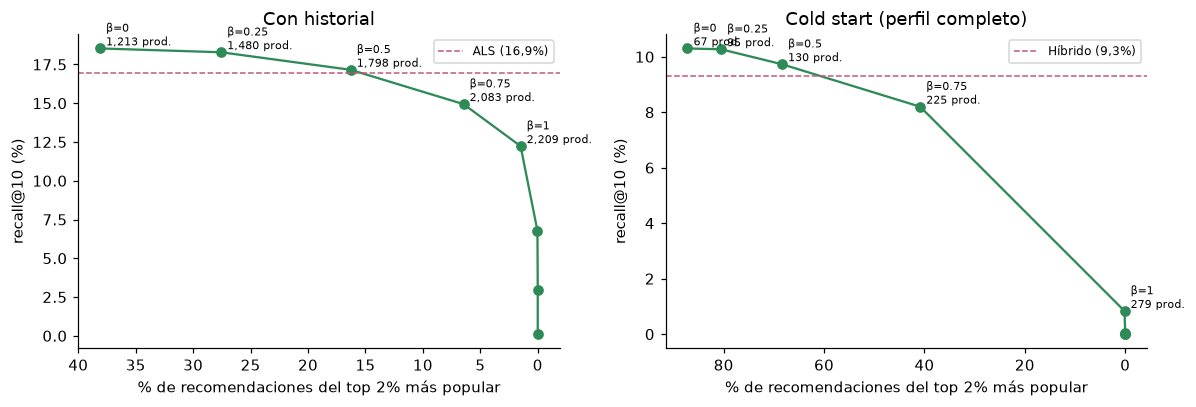

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, esc, linea, lab in [(axes[0], "con historial", 16.93, "ALS (16,9%)"), (axes[1], "cold start", 9.31, "Híbrido (9,3%)")]:
    p = pop[pop.escenario == esc]
    ax.plot(p["% top 2% popular"] * 100, p.recall * 100, "o-", color=VERDE)
    for _, r in p[p.beta <= 1].iterrows():
        ax.annotate(f"β={r.beta:g}\n{r['productos distintos']:,.0f} prod.", (r["% top 2% popular"] * 100, r.recall * 100),
                    fontsize=7, xytext=(4, 2), textcoords="offset points")
    ax.axhline(linea, color="#c2577a", lw=1, ls="--", label=lab)
    ax.set(title=esc.capitalize() + (" (perfil completo)" if esc == "cold start" else ""),
           xlabel="% de recomendaciones del top 2% más popular", ylabel="recall@10 (%)")
    ax.invert_xaxis()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "04_popularidad_tradeoff.png", bbox_inches="tight")
plt.show()

Cada punto es un valor de $\beta$. Hacia la derecha del gráfico, las recomendaciones son menos "lo de siempre"; hacia abajo, se acierta menos.

**Una regla para elegir $\beta$:** el más grande que **todavía le gana al mejor baseline en cold start** (9,3%). Es decir, diversificar todo lo posible sin perder la ventaja de la red.

In [14]:
cs = pop[pop.escenario == "cold start"].set_index("beta")
BETA = cs.index[cs.recall >= 0.0931].max()
print(f"β elegido: {BETA}")
display(pop[pop.beta.isin([0, BETA])].set_index(["escenario", "beta"]))

β elegido: 0.5


,,recall,productos distintos,cobertura,% top 2% popular
escenario,beta,,,,
con historial,0.0000,0.1853,1213,0.5160,0.3811
cold start,0.0000,0.1030,67,0.0285,0.8722
con historial,0.5000,0.1716,1798,0.7648,0.1629
cold start,0.5000,0.0973,130,0.0553,0.6838


**Cómo leerlo:**

- **β = 0,25 es diversificación "gratis"**: en cold start pasa de 67 a 95 productos distintos (+40%) **sin perder recall** (10,3%). Con historial, de 1.213 a 1.480 productos, perdiendo 0,2 puntos.
- **β = 0,5 es la elegida por la regla**: en cold start recomienda **el doble de productos distintos (130)** y baja del 87% al 68% de recomendaciones del top 2%, perdiendo 0,6 puntos de recall (9,7%, todavía por encima del híbrido). Con historial el efecto es enorme: 1.798 productos (77% del catálogo), solo 16% del top 2%, y **sigue ganándole al ALS** (17,2% contra 16,9%).
- **A partir de β = 1, se rompe**: la penalización domina el puntaje y la red recomienda productos casi sin reseñas. El recall en cold start se desploma a casi 0.

**Conclusión:** hay margen para diversificar a bajo costo. Un sistema real podría elegir β según qué le importe más: acertar o mostrar variedad.

## 5 · La evaluación final: test

Hasta acá **todas** las decisiones (hiperparámetros, épocas, $eta$) se tomaron mirando validación. Ahora evaluamos todo **una sola vez** en test: personas y productos que ninguna decisión vio.

### El protocolo: re-entrenar con todo lo que no es test

Una vez elegidos los hiperparámetros, la práctica estándar es **re-entrenar cada modelo con todo lo que no es test** (train + las dos validaciones) y recién ahí evaluar. Es lo que haría una empresa: no tiraría los datos de validación a la hora de poner el modelo en producción.

- Los baselines se re-ajustan con esos datos (mismos hiperparámetros).
- La red se re-entrena con `scripts/train_final.py` (misma configuración, 10 épocas fijas porque ya no hay validación para elegir la época).
- **Con historial**: el producto escondido es el del **último** día de cada persona. Los modelos conocen todo lo anterior, incluido su producto de validación, y no se lo vuelven a recomendar.
- **Cold start**: otras ~21.500 personas nuevas, distintas de las de validación (comparamos sobre las que tienen perfil completo).

> **Un error que cometimos y corregimos.** La primera vez evaluamos test con los modelos entrenados *solo* con train. El recall con historial se desplomaba (two-tower 18,5% → 11,1%; ALS 16,9% → 8,7%). La causa: los modelos no conocían el producto de validación, que es **el más reciente** de cada persona y el que mejor predice el siguiente. Con ese producto, la red sube a 13,6% sin re-entrenar (el historial es solo una entrada) y el ALS re-entrenado a 14,8%. Por eso re-entrenamos **todos** los modelos, para que la comparación sea justa. Lección: **el protocolo de test tiene que darles a todos los modelos la misma información, y la misma que tendrían en la vida real.**

In [15]:
todo = pd.concat([s.train, s.val_warm, s.val_cold], ignore_index=True)  # todo lo que no es test
print(f"Datos para los modelos finales: {len(todo):,} positivos (train: {len(s.train):,})")

def test_warm(m):
    return evaluate(m, s.test_warm, todo, s.users, idx, exclude_train=True)

def test_cold(m):
    r = evaluate(m, s.test_cold, todo, s.users, idx, exclude_train=False)
    return r[r.index.isin(completo)]

pop_m = Popularity(todo, idx)
seg = SegmentPopularity(todo, s.users, idx, cols=PROFILE_COLS, alpha=100)
als = ALSRecommender(todo, idx, factors=64, regularization=20, alpha=50)
hib = ProfileToALS(als, todo, s.users, min_pos=1, ridge_alpha=1000)
tt = TwoTowerRecommender(todo, s.users, s.items, idx, weights=ROOT / "models" / "two_tower_final.pt", **KW)
tt_div = PopularityPenalty(tt, todo, idx, beta=BETA, scale=1 / 0.05)

test = {
    ("Con historial", "Popularidad"): test_warm(pop_m),
    ("Con historial", "ALS"): test_warm(als),
    ("Con historial", "Two-tower"): test_warm(tt),
    ("Con historial", f"Two-tower diversificada (β={BETA})"): test_warm(tt_div),
    ("Cold start", "Popularidad"): test_cold(pop_m),
    ("Cold start", "Pop. por segmento"): test_cold(seg),
    ("Cold start", "Híbrido perfil→ALS"): test_cold(hib),
    ("Cold start", "Two-tower"): test_cold(tt),
    ("Cold start", f"Two-tower diversificada (β={BETA})"): test_cold(tt_div),
}
tabla_test = pd.DataFrame({k: summarize(r, N) for k, r in test.items()}).T
tabla_test.index.names = ["escenario", "modelo"]
tabla_test.to_csv(ROOT / "reports" / "04_test.csv")
print("TEST · cold start = personas con perfil completo")
tabla_test

Datos para los modelos finales: 783,409 positivos (train: 697,572)


C:\Users\cande\Universidad Austral\Recomendador Skincare\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TEST · cold start = personas con perfil completo


recall@10  ± recall  ndcg@10  \
escenario     modelo                                                          
Con historial Popularidad                         0.0354    0.0009   0.0195   
              ALS                                 0.1500    0.0018   0.0822   
              Two-tower                           0.1518    0.0018   0.0870   
              Two-tower diversificada (β=0.5)     0.1404    0.0017   0.0794   
Cold start    Popularidad                         0.0754    0.0019   0.0506   
              Pop. por segmento                   0.0883    0.0020   0.0582   
              Híbrido perfil→ALS                  0.0891    0.0020   0.0573   
              Two-tower                           0.1021    0.0022   0.0634   
              Two-tower diversificada (β=0.5)     0.0978    0.0021   0.0606   

                                               ± ndcg  cobertura    personas  
escenario     modelo                                                          
Con historial Popularidad                      0.0006     0.0094 41,509.0000  
              ALS                              0.0011     0.4964 41,509.0000  
              Two-tower                        0.0011     0.5534 41,509.0000  
              Two-tower diversificada (β=0.5)  0.0011     0.7933 41,509.0000  
Cold start    Popularidad                      0.0013     0.0043 16,228.0000  
              Pop. por segmento                0.0014     0.1944 16,228.0000  
              Híbrido perfil→ALS               0.0014     0.0340 16,228.0000  
              Two-tower                        0.0014     0.0281 16,228.0000  
              Two-tower diversificada (β=0.5)  0.0014     0.0532 16,228.0000

In [16]:
val03 = pd.read_csv(ROOT / "reports" / "03_two_tower_val.csv").set_index(["escenario", "modelo"])["recall@10"]
comp = pd.DataFrame({"validación": val03, "test": tabla_test["recall@10"]}).dropna()
comp["diferencia (puntos)"] = (comp.test - comp["validación"]) * 100

dif_test = pd.DataFrame(
    [pareada(test[("Con historial", "Two-tower")], test[("Con historial", "ALS")]),
     pareada(test[("Cold start", "Two-tower")], test[("Cold start", "Híbrido perfil→ALS")]),
     pareada(test[("Cold start", "Two-tower")], test[("Cold start", "Pop. por segmento")])],
    columns=["diferencia (puntos)", "± 95%"],
    index=["Two-tower − ALS (con historial)", "Two-tower − Híbrido (cold start)", "Two-tower − Pop. por segmento (cold start)"])
display(comp.style.format({"validación": "{:.2%}", "test": "{:.2%}", "diferencia (puntos)": "{:+.2f}"}).set_caption("¿Test se parece a validación?"))
dif_test.style.format({"diferencia (puntos)": "{:+.2f}", "± 95%": "{:.2f}"}).set_caption("Diferencias pareadas en test")

,diferencia (puntos),± 95%
Two-tower − ALS (con historial),+0.17,0.32
Two-tower − Híbrido (cold start),+1.30,0.32
Two-tower − Pop. por segmento (cold start),+1.38,0.34


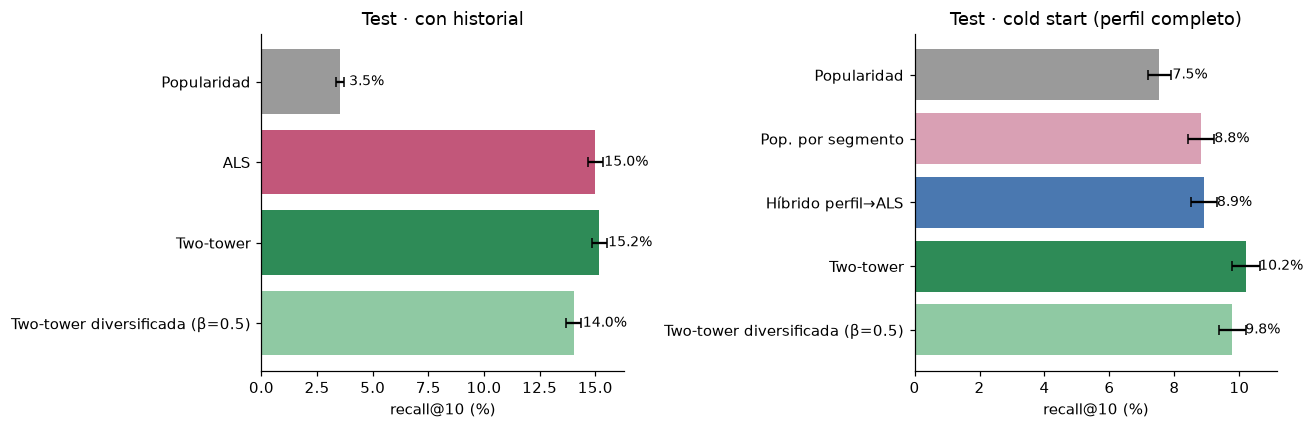

In [17]:
COL = {"Popularidad": GRIS, "Pop. por segmento": "#d9a0b4", "ALS": "#c2577a", "Híbrido perfil→ALS": "#4a78b0",
       "Two-tower": VERDE, f"Two-tower diversificada (β={BETA})": "#8fc9a3"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, esc, titulo in [(axes[0], "Con historial", "Test · con historial"), (axes[1], "Cold start", "Test · cold start (perfil completo)")]:
    t = tabla_test.loc[esc]
    ax.barh(t.index, t["recall@10"] * 100, xerr=1.96 * t["± recall"] * 100, color=[COL[m] for m in t.index], capsize=3)
    for i, v in enumerate(t["recall@10"] * 100):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=titulo, xlabel="recall@10 (%)")
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG / "04_test.png", bbox_inches="tight")
plt.show()

In [18]:
filas = []
for (esc, m) in [("Con historial", "ALS"), ("Con historial", "Two-tower"),
                 ("Cold start", "Híbrido perfil→ALS"), ("Cold start", "Two-tower")]:
    filas.append(by_tone(test[(esc, m)]).drop(index="desconocido", errors="ignore").assign(escenario=esc, modelo=m))
tono_test = pd.concat(filas).rename_axis("tone_group").reset_index()
tono_test.to_csv(ROOT / "reports" / "04_test_por_tono.csv", index=False)
display((tono_test.pivot_table(index=["escenario", "modelo"], columns="tone_group", values="mean")[TONE_GROUP_ORDER] * 100).round(2))
display(tono_test.pivot_table(index=["escenario", "modelo"], columns="tone_group", values="±")[TONE_GROUP_ORDER].mul(196).round(2)
        .style.set_caption("± 95% (puntos)"))

tone_group                         claro   light   medio     tan  oscuro
escenario     modelo                                                    
Cold start    Híbrido perfil→ALS  8.4700  8.8600  9.0000  9.8300 11.0000
              Two-tower           9.6500  9.9600 10.4300 12.1800 12.3800
Con historial ALS                14.5700 14.7300 15.3200 16.2100 14.1700
              Two-tower          14.3800 14.6100 15.6000 17.0700 15.5300

**Cómo leerlo:**

**Cold start: la red gana, y el resultado se reproduce casi exacto.** 10,2% en test contra 10,3% en validación. Le gana al híbrido por **+1,3 ± 0,3 puntos** y a la popularidad por segmento por +1,4. Los baselines bajan un poco más (−0,4 puntos), así que la ventaja de la red incluso crece un poco.

**Con historial: empate con el ALS.** 15,2% contra 15,0%: la diferencia (+0,2 ± 0,3) **no es significativa**. La red acierta un poco más arriba en la lista (NDCG 0,087 contra 0,082) y recomienda más variedad (55% del catálogo contra 50%), pero la ventaja de 1,6 puntos que vimos en validación no se sostiene.

¿Por qué se achicó la ventaja?
- **Test es más difícil para todos**: el producto del último día es menos predecible (hasta la popularidad baja de 4,7% a 3,5%).
- **Optimismo de validación**: elegimos la configuración de la red y su mejor época mirando validación, y eso infla un poco el resultado de validación. Es justamente para detectar esto que existe test.
- **El producto más reciente**: el diagnóstico del error de protocolo mostró que el producto más reciente es muy informativo. El ALS lo aprovecha bien; la red promedia todo el historial **con el mismo peso**, sin saber cuál es el más reciente. Darle más peso a lo reciente es una mejora natural para la red.

**Por tono, en test**: con historial, la red queda empatada con el ALS en los grupos grandes y gana en *tan* y *oscuro*. En cold start gana en todos los grupos. Ningún grupo queda peor.

## 6 · Conclusiones

### El resultado final (test)

| Escenario | Mejor baseline | Two-tower | Diferencia (±95%) | Veredicto |
|---|---|---|---|---|
| **Cold start** (perfil completo) | Híbrido: 8,9% | **10,2%** | +1,3 ± 0,3 | **La red gana** (+15% relativo) |
| **Con historial** | ALS: 15,0% | **15,2%** | +0,2 ± 0,3 | **Empate** |

### Lo que aprendimos

**1. La red gana donde importa para la pregunta del proyecto.** *"Si me decís tu tipo y tono de piel, ¿te puedo recomendar algo aunque nunca hayas reseñado nada?"* Sí, y la red lo hace mejor que cualquier baseline, con un resultado que se reproduce en test. Con historial, empata con el ALS: el historial ya dice casi todo.

**2. Cada pieza tiene su escenario.** El perfil solo sirve en cold start. El historial es la pieza más importante. El contenido (marca, ingredientes, highlights) es lo que le permite a la red alcanzar al ALS. El ID casi no hace falta, así que la red puede recomendar productos nuevos.

**3. El perfil es especialmente valioso para los tonos oscuros.** En cold start, conocer el tono le suma +3,7 puntos al grupo *oscuro*, más que a cualquier otro. Sin perfil, todos recibirían lo que les gusta a las mayorías.

**4. No encontramos una brecha en contra de ningún grupo de tono.** Ni en validación ni en test, ni con historial ni en cold start. El aparente problema con *tan* era ruido.

**5. Pero los datos de los tonos chicos tienen un sesgo de origen.** Las personas *dark*, *porcelain* y *olive* reseñan casi solo productos de dos marcas. La red aprende eso y "acierta", pero no es personalización real. **Una métrica alta en un grupo chico puede esconder un sesgo de los datos**: hay que mirar *qué* se recomienda, no solo cuánto se acierta.

**6. Se puede diversificar a bajo costo.** Penalizando la popularidad (β = 0,25 a 0,5), la red recomienda entre 40% y 100% más productos distintos, perdiendo poco o nada de recall.

**7. Un error de protocolo que vale la pena contar.** La primera evaluación en test les ocultaba a los modelos el producto más reciente de cada persona. Re-entrenar todo con "todo lo que no es test" lo corrigió y cambió la conclusión con historial (de "la red gana" a "empate"). **Sin test, hubiéramos reportado una ventaja que no existe.**

### Ideas para seguir
- **Darle más peso a lo reciente** en el historial (por ejemplo, con atención o con un descuento por antigüedad). Es la mejora más prometedora con historial.
- **Marcar o filtrar las reseñas con origen sesgado** (los tonos chicos) antes de entrenar.
- Una **demo** donde elegís tu piel y ves tu top 10, con un control de "más variedad".